# Random agent performance on CartPole-v1

In [66]:
import gymnasium as gym
import jax
import jax.numpy as jnp
from tqdm import tqdm
import matplotlib.pyplot as plt

import qnrl

In [67]:
total_timesteps = 20_000
seed = 0

In [68]:
# Make environment.
env = gym.make('CartPole-v1')
env = gym.wrappers.RecordEpisodeStatistics(env) # Track statistics for every episode.
env = gym.wrappers.Autoreset(env) # Automatically reset the environment (continuous training).

In [69]:
env.reset(seed=seed)
env.action_space.seed(seed)

history_list = [] # List of history metrics.
pbar = tqdm(range(total_timesteps), unit='step', leave=True)
pbar_postfix = dict() # Current progress bar postfix content.
for t in pbar:
    # Take random action.
    action = env.action_space.sample()
    
    # Interaction within environment using selected actions.
    next_observation, reward, done, truncation, info = env.step(action)
    
    # Record episode statistics.
    if "episode" in info:
        meta = dict(
            episode_step=t,
            episode_reward=info['episode']['r'],
            episode_length=info['episode']['l'],
            episode_time=info['episode']['t'],
        )
        history_list.append(meta)
        pbar_postfix.update(**meta)
        pbar.set_postfix(pbar_postfix)

# Convert history metrics to dictionary.
history_dict = qnrl.tools.listofdict_to_dictoflist(history_list)

100%|██████████| 20000/20000 [00:00<00:00, 55802.03step/s, episode_step=2e+4, episode_reward=31, episode_length=31, episode_time=0.000158] 


Text(0, 0.5, 'episode_reward')

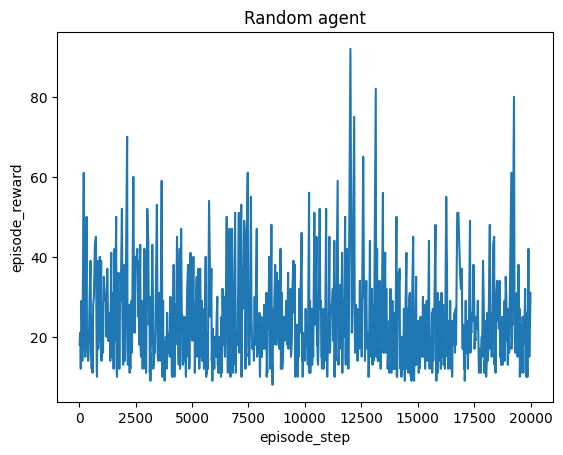

In [70]:
plt.figure()
plt.title("Random agent")
plt.plot(history_dict['episode_step'], history_dict['episode_reward'])
plt.xlabel('episode_step')
plt.ylabel('episode_reward')